# 2. Player profiles: creators, carriers and shooters

**Questions**
1. Does xT measure something different from xG, or are they the same skill under another name?
2. What attacking archetypes appear once players are described by how they progress the ball and create chances?
3. How much of a player's role can be recovered from their event profile alone?

**Population:** outfield players with at least 900 league minutes (10 full matches), so per-90 rates aren't dominated by small samples.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.metrics import ConfusionMatrixDisplay, silhouette_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

from epl_xt import config
from epl_xt.plotting import (DIVERGING, MUTED, POSITION_COLORS, SEQUENTIAL, SERIES, SURFACE,
                             TEXT_SECONDARY, apply_style, save)

apply_style()
pd.set_option("display.precision", 3)
RANDOM_STATE = 42

season = pd.read_parquet(config.PLAYER_SEASON_TABLE)
players = season[(season["minutes"] >= 900) & (season["position_group"] != "GK")].reset_index(drop=True)
print(f"{len(players)} players")
players["position_group"].value_counts()

300 players


position_group
DEF    119
MID    102
FWD     79
Name: count, dtype: int64

## Features

Every feature is a per-90 rate (or a ratio), so a player's profile doesn't depend on how much they played.

| feature | what it captures |
|---|---|
| `xt_pass_p90`, `xt_carry_p90` | threat added by passing and by carrying |
| `npxg_p90`, `shots_p90` | shot volume and quality (non-penalty) |
| `passes_into_box_p90`, `box_entries_p90` | getting the ball into the penalty area, by pass or by any move |
| `final_third_entries_p90` | moving the ball from midfield into the final third |
| `passes_p90`, `carries_p90`, `pass_completion` | involvement and security in possession |

In [2]:
XT_FEATURES = ["xt_pass_p90", "xt_carry_p90"]
FEATURES = XT_FEATURES + [
    "npxg_p90", "shots_p90", "passes_into_box_p90", "box_entries_p90",
    "final_third_entries_p90", "passes_p90", "carries_p90", "pass_completion",
]
players[FEATURES].describe().T[["mean", "std", "min", "50%", "max"]]

,mean,std,min,50%,max
xt_pass_p90,0.063,0.046,-0.040,0.055,0.240
xt_carry_p90,0.033,0.029,-0.031,0.025,0.147
npxg_p90,0.115,0.116,0.000,0.070,0.562
shots_p90,1.272,0.971,0.000,0.942,4.746
passes_into_box_p90,0.753,0.621,0.000,0.671,3.609
box_entries_p90,1.286,1.113,0.000,1.014,6.096
final_third_entries_p90,4.405,2.214,0.610,4.157,13.484
passes_p90,43.125,13.264,14.782,43.047,87.645
carries_p90,33.586,10.900,10.594,33.476,73.487
pass_completion,0.767,0.073,0.553,0.775,0.914


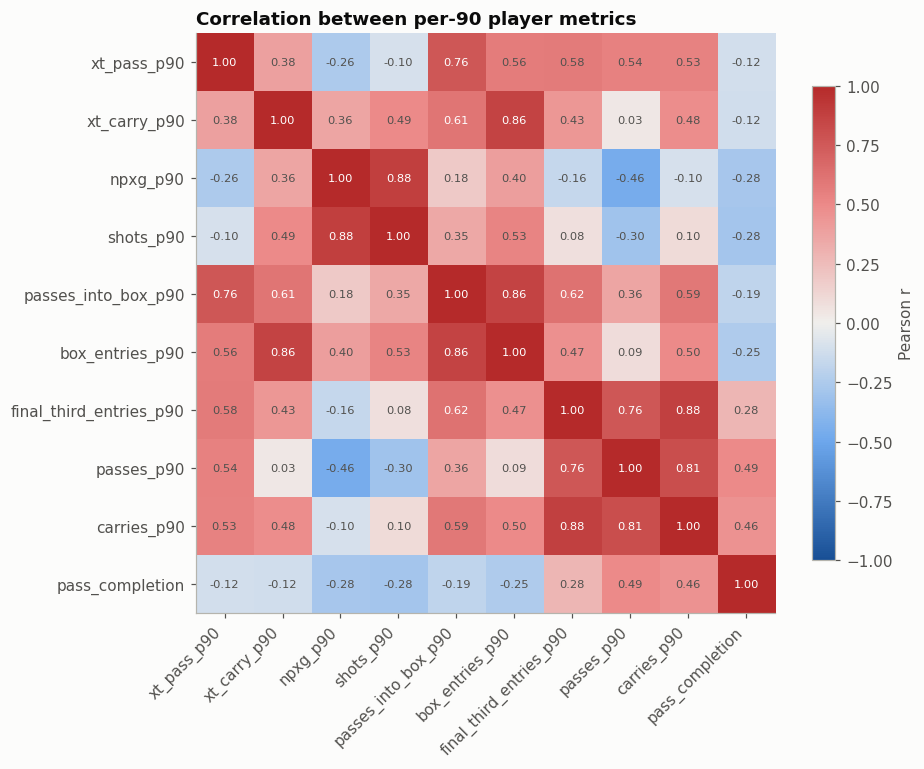

In [3]:
corr = players[FEATURES].corr()
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=45, ha="right")
ax.set_yticks(range(len(FEATURES)), FEATURES)
ax.grid(False)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else TEXT_SECONDARY)
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson r")
ax.set_title("Correlation between per-90 player metrics")
save(fig, "player_feature_correlations")
plt.show()

## Q1. Is xT just xG by another name?

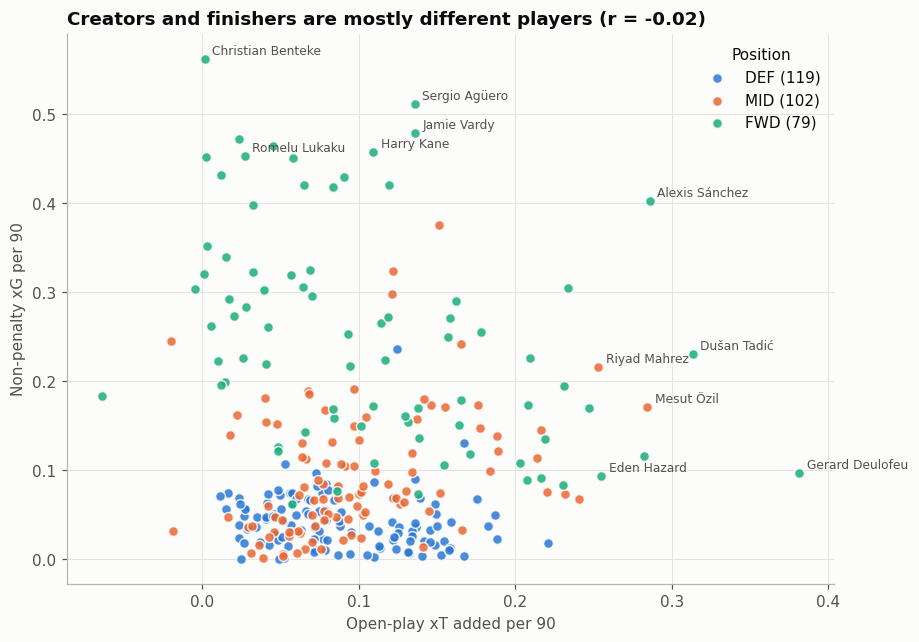

In [4]:
players["xt_p90"] = players["xt_pass_p90"] + players["xt_carry_p90"]
r = players[["xt_p90", "npxg_p90"]].corr().iloc[0, 1]

fig, ax = plt.subplots(figsize=(9, 6.5))
for group, color in POSITION_COLORS.items():
    d = players[players["position_group"] == group]
    ax.scatter(d["xt_p90"], d["npxg_p90"], s=42, color=color, alpha=0.85,
               edgecolor=SURFACE, linewidth=1, label=f"{group} ({len(d)})")
LABELLED = ["Mesut Özil", "Gerard Deulofeu", "Dušan Tadić", "Alexis Sánchez", "Eden Hazard", "Riyad Mahrez",
            "Sergio Agüero", "Jamie Vardy", "Harry Kane", "Christian Benteke", "Romelu Lukaku"]
for _, p in players[players["player"].isin(LABELLED)].iterrows():
    ax.annotate(p["player"], (p["xt_p90"], p["npxg_p90"]), xytext=(5, 3), textcoords="offset points",
                fontsize=8, color=TEXT_SECONDARY)
ax.set_xlabel("Open-play xT added per 90")
ax.set_ylabel("Non-penalty xG per 90")
ax.set_title(f"Creators and finishers are mostly different players (r = {r:.2f})")
ax.legend(title="Position", loc="upper right")
save(fig, "creators_vs_finishers")
plt.show()

In [5]:
by_group = players.groupby("position_group")[["xt_pass_p90", "xt_carry_p90", "npxg_p90"]].median()
by_group.loc[["DEF", "MID", "FWD"]]

,xt_pass_p90,xt_carry_p90,npxg_p90
position_group,,,
DEF,0.059,0.015,0.037
MID,0.056,0.027,0.074
FWD,0.035,0.052,0.230


## Q2. Archetypes: PCA, then k-means

The ten features are highly collinear (for example, passes and final-third entries correlate at 0.76), so they are standardised and reduced with PCA before clustering.

In [6]:
X = StandardScaler().fit_transform(players[FEATURES])
pca = PCA(random_state=RANDOM_STATE).fit(X)
explained = pd.DataFrame({
    "explained": pca.explained_variance_ratio_,
    "cumulative": pca.explained_variance_ratio_.cumsum(),
    "eigenvalue": pca.explained_variance_,
}, index=[f"PC{i + 1}" for i in range(len(FEATURES))])
explained.head(6)

,explained,cumulative,eigenvalue
PC1,0.447,0.447,4.485
PC2,0.303,0.750,3.041
PC3,0.125,0.875,1.249
PC4,0.052,0.927,0.521
PC5,0.030,0.957,0.306
PC6,0.016,0.973,0.158


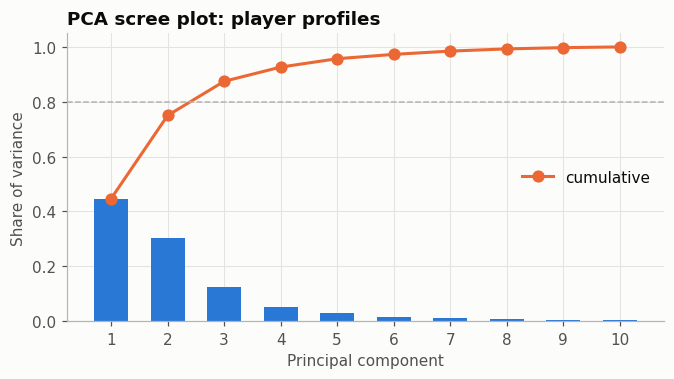

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.4))
pcs = np.arange(1, len(FEATURES) + 1)
ax.bar(pcs, explained["explained"], color=SERIES[0], width=0.6)
ax.plot(pcs, explained["cumulative"], color=SERIES[1], marker="o", label="cumulative")
ax.axhline(0.8, color=MUTED, lw=1, ls="--")
ax.set_xticks(pcs)
ax.set_xlabel("Principal component")
ax.set_ylabel("Share of variance")
ax.set_title("PCA scree plot: player profiles")
ax.legend(loc="center right")
plt.show()

In [8]:
N_PC = int((explained["cumulative"] < 0.8).sum() + 1)
loadings = pd.DataFrame(pca.components_[:N_PC].T, index=FEATURES,
                        columns=[f"PC{i + 1}" for i in range(N_PC)])
print(f"Keeping {N_PC} components ({explained['cumulative'].iloc[N_PC - 1]:.0%} of variance)")
loadings.style.background_gradient(cmap=DIVERGING, vmin=-0.7, vmax=0.7).format("{:.2f}")

Keeping 3 components (87% of variance)


,PC1,PC2,PC3
xt_pass_p90,0.36,-0.12,-0.47
xt_carry_p90,0.34,0.25,0.05
npxg_p90,0.04,0.49,0.35
shots_p90,0.15,0.47,0.34
passes_into_box_p90,0.42,0.11,-0.22
box_entries_p90,0.39,0.27,-0.11
final_third_entries_p90,0.40,-0.19,0.14
passes_p90,0.28,-0.41,0.11
carries_p90,0.40,-0.20,0.29
pass_completion,0.04,-0.36,0.60


* **PC1, overall involvement in progression (45%).** Every progression metric loads positively: box entries, final-third entries, carries and both xT terms. High scores are players the team routes attacks through.
* **PC2, shooting vs build-up (30%).** npxG and shots on one side, passing volume and completion on the other. This separates strikers from deep playmakers at similar involvement levels.
* **PC3, safe vs risky passing (13%).** Pass completion against xT from passing. It separates recyclers, who complete many low-value passes, from players who attempt the dangerous ones.

In [9]:
scores = pca.transform(X)[:, :N_PC]
ks = range(2, 9)
sil = [silhouette_score(scores, KMeans(k, n_init=20, random_state=RANDOM_STATE).fit_predict(scores)) for k in ks]
inertia = [KMeans(k, n_init=20, random_state=RANDOM_STATE).fit(scores).inertia_ for k in ks]
pd.DataFrame({"silhouette": sil, "inertia": inertia}, index=pd.Index(ks, name="k"))

,silhouette,inertia
k,,
2,0.292,1784.559
3,0.329,1288.674
4,0.323,984.104
5,0.329,830.435
6,0.299,722.542
7,0.303,641.214
8,0.301,592.183


Silhouette scores are modest for every *k* (about 0.3), which is normal for player data: roles blend into each other rather than forming separate islands. **k = 3 and k = 5 tie for the best silhouette (0.33)**. We use k = 5 because it splits the coarse defender / midfielder / attacker grouping into roles a scout would recognise. Each cluster is then described by its average z-scored profile.

In [10]:
K = 5
kmeans = KMeans(K, n_init=50, random_state=RANDOM_STATE).fit(scores)
players["cluster"] = kmeans.labels_

profile = pd.DataFrame(X, columns=FEATURES).groupby(players["cluster"]).mean()
profile["n"] = players["cluster"].value_counts().sort_index()
profile["DEF/MID/FWD"] = players.groupby("cluster")["position_group"].apply(
    lambda s: "/".join(str((s == g).sum()) for g in ["DEF", "MID", "FWD"]))
print(f"k = {K}")
profile.round(2)

k = 5


,xt_pass_p90,xt_carry_p90,npxg_p90,shots_p90,passes_into_box_p90,box_entries_p90,final_third_entries_p90,passes_p90,carries_p90,pass_completion,n,DEF/MID/FWD
cluster,,,,,,,,,,,,
0,1.70,1.49,0.34,0.77,2.29,2.03,1.70,1.23,1.72,0.16,24,1/11/12
1,-0.49,-0.75,-0.52,-0.69,-0.80,-0.86,-0.74,-0.34,-0.74,0.18,98,71/24/3
2,0.33,1.10,0.45,0.68,0.60,1.05,0.07,-0.55,0.20,-0.71,47,4/19/24
3,0.37,-0.16,-0.59,-0.47,0.07,-0.19,0.70,0.85,0.61,0.48,92,43/45/4
4,-1.07,0.01,1.93,1.56,-0.32,0.09,-0.91,-1.26,-0.88,-0.84,39,0/3/36


In [11]:
for c in range(K):
    members = players[players["cluster"] == c].sort_values("minutes", ascending=False)
    print(f"Cluster {c}: " + ", ".join(members["player"].head(10)))

Cluster 0: Ross Barkley, Mesut Özil, Christian Eriksen, Cesc Fàbregas, Willian, Aaron Ramsey, Dimitri Payet, James Milner, Alexis Sánchez, Yaya Touré
Cluster 1: Wes Morgan, Craig Dawson, Darren Fletcher, Ashley Williams, Steve Cook, José Fonte, Robert Huth, Scott Dann, Georginio Wijnaldum, Chris Smalling
Cluster 2: Troy Deeney, Moussa Sissoko, Patrick van Aanholt, Robert Brady, Riyad Mahrez, Matt Ritchie, Marko Arnautović, Marc Albrighton, Anthony Martial, Jason Puncheon
Cluster 3: Simon Francis, Andrew Surman, Toby Alderweireld, Aaron Cresswell, Charlie Daniels, Nacho Monreal, Eric Dier, Héctor Bellerín, César Azpilicueta, Mark Noble
Cluster 4: Harry Kane, Jamie Vardy, Romelu Lukaku, Odion Ighalo, Gylfi Sigurðsson, André Ayew, Jermain Defoe, Salomón Rondón, Olivier Giroud, Diego Costa


Reading the profiles and the players in each cluster gives five recognisable roles:

| cluster | archetype | profile | typical players |
|---|---|---|---|
| 0 | **Elite creator** | top of the league on xT from passes *and* carries and on getting the ball into the box | Özil, Eriksen, Fàbregas, Payet, Alexis |
| 1 | **Low-involvement defender** | below average on almost everything with the ball | Wes Morgan, Huth, Fonte, Smalling |
| 2 | **Wide carrier** | high xT from carrying and many box entries, low pass completion | Mahrez, Martial, Sissoko, Albrighton |
| 3 | **Build-up player** | high passing volume, accuracy and final-third entries, little shooting | Bellerín, Azpilicueta, Dier, Alderweireld |
| 4 | **Box finisher** | highest npxG and shots, lowest involvement in build-up | Kane, Vardy, Lukaku, Giroud |

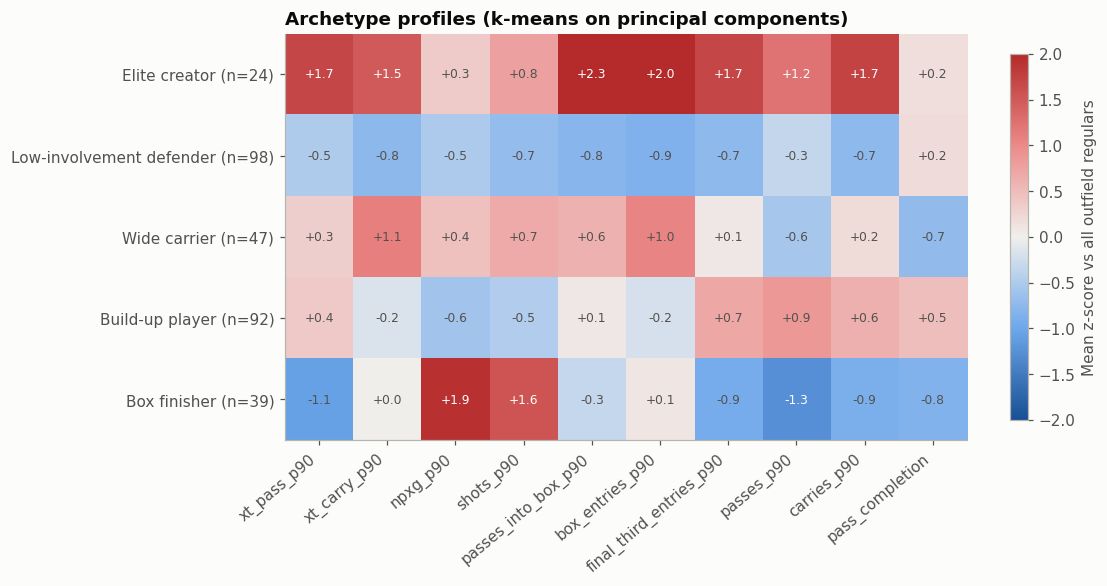

In [12]:
ARCHETYPES = {0: "Elite creator", 1: "Low-involvement defender", 2: "Wide carrier",
              3: "Build-up player", 4: "Box finisher"}
# Guard the hand-written names against the cluster numbering changing.
cluster_of = players.set_index("player")["cluster"]
assert cluster_of["Mesut Özil"] == 0 and cluster_of["Harry Kane"] == 4 and cluster_of["Riyad Mahrez"] == 2
players["archetype"] = players["cluster"].map(ARCHETYPES)

z = profile[FEATURES].rename(index=ARCHETYPES)
fig, ax = plt.subplots(figsize=(10, 0.6 * K + 1.8))
im = ax.imshow(z, cmap=DIVERGING, vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=40, ha="right")
ax.set_yticks(range(K), [f"{name} (n={n})" for name, n in zip(z.index, profile["n"])])
ax.grid(False)
for i in range(K):
    for j in range(len(FEATURES)):
        ax.text(j, i, f"{z.iloc[i, j]:+.1f}", ha="center", va="center", fontsize=8,
                color="white" if abs(z.iloc[i, j]) > 1.2 else TEXT_SECONDARY)
fig.colorbar(im, ax=ax, label="Mean z-score vs all outfield regulars", shrink=0.9)
ax.set_title("Archetype profiles (k-means on principal components)")
save(fig, "player_archetypes")
plt.show()

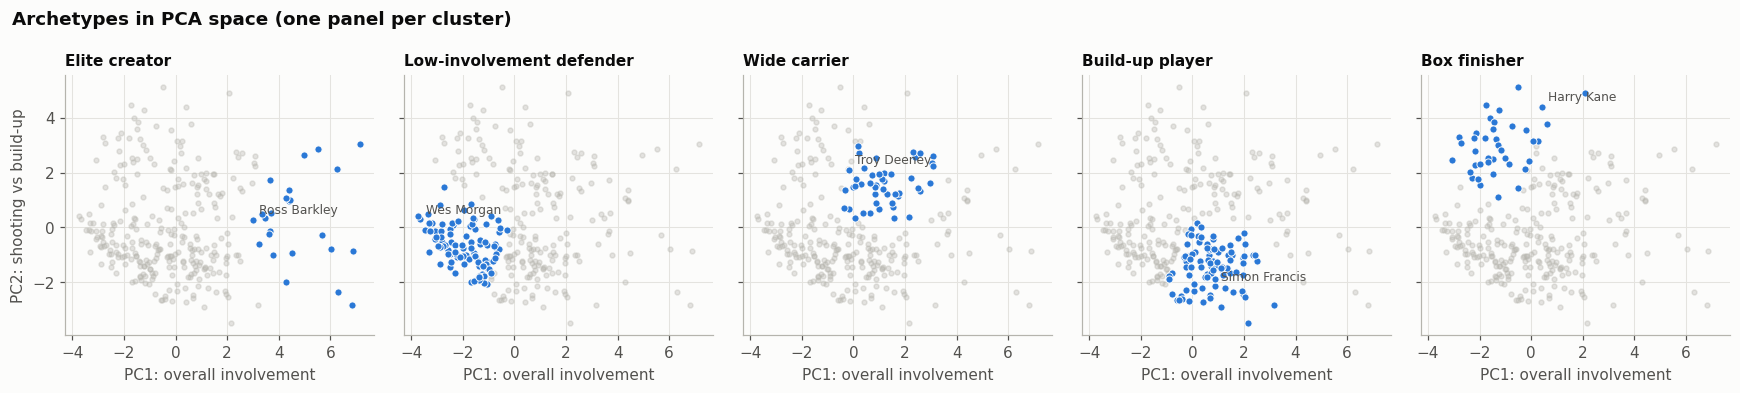

In [13]:
fig, axes = plt.subplots(1, K, figsize=(3.2 * K, 3.6), sharex=True, sharey=True)
for c, ax in enumerate(axes):
    inside = players["cluster"] == c
    ax.scatter(scores[~inside, 0], scores[~inside, 1], s=10, color=MUTED, alpha=0.35)
    ax.scatter(scores[inside, 0], scores[inside, 1], s=22, color=SERIES[0], edgecolor=SURFACE, linewidth=0.6)
    i = players[inside]["minutes"].idxmax()
    ax.annotate(players.loc[i, "player"], (scores[i, 0], scores[i, 1]), xytext=(4, 4),
                textcoords="offset points", fontsize=8, color=TEXT_SECONDARY)
    ax.set_title(ARCHETYPES[c], fontsize=10)
    ax.set_xlabel("PC1: overall involvement")
axes[0].set_ylabel("PC2: shooting vs build-up")
fig.suptitle("Archetypes in PCA space (one panel per cluster)", x=0.01, ha="left", fontweight="semibold")
fig.tight_layout()
save(fig, "player_archetypes_pca")
plt.show()

## Q3. Can the profile recover a player's position?

A supervised check on the same features: predict DEF / MID / FWD with **k-nearest neighbours** and a **decision tree**. Hyperparameters are tuned with an inner 5-fold CV, and performance is estimated with an outer stratified 5-fold CV (nested CV), so no test fold is ever used for tuning. Each model is fitted twice, with and without the two xT features, to measure what xT adds.

In [14]:
y = players["position_group"]
outer = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
inner = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE + 1)

models = {
    "Majority class": DummyClassifier(strategy="most_frequent"),
    "KNN": GridSearchCV(make_pipeline(StandardScaler(), KNeighborsClassifier()),
                        {"kneighborsclassifier__n_neighbors": range(3, 32, 2),
                         "kneighborsclassifier__weights": ["uniform", "distance"]}, cv=inner),
    "Decision tree": GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE),
                                  {"max_depth": range(2, 9), "min_samples_leaf": [5, 10, 20]}, cv=inner),
}
feature_sets = {"with xT": FEATURES, "without xT": [f for f in FEATURES if f not in XT_FEATURES]}

rows = []
for model_name, model in models.items():
    for set_name, cols in feature_sets.items():
        acc = cross_val_score(model, players[cols], y, cv=outer, scoring="accuracy")
        f1 = cross_val_score(model, players[cols], y, cv=outer, scoring="f1_macro")
        rows.append({"model": model_name, "features": set_name, "accuracy": acc.mean(),
                     "accuracy_sd": acc.std(), "macro_f1": f1.mean()})
results = pd.DataFrame(rows)
results

,model,features,accuracy,accuracy_sd,macro_f1
0,Majority class,with xT,0.397,0.007,0.189
1,Majority class,without xT,0.397,0.007,0.189
2,KNN,with xT,0.787,0.031,0.775
3,KNN,without xT,0.773,0.069,0.757
4,Decision tree,with xT,0.710,0.040,0.701
5,Decision tree,without xT,0.690,0.048,0.690


Tuned KNN on all data: {'kneighborsclassifier__n_neighbors': 19, 'kneighborsclassifier__weights': 'distance'}


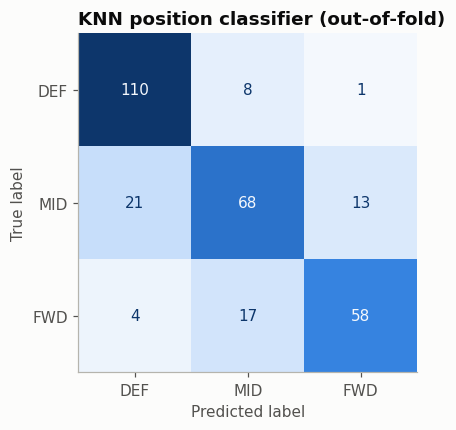

In [15]:
best = models["KNN"].fit(players[FEATURES], y)
print("Tuned KNN on all data:", best.best_params_)
pred = cross_val_predict(models["KNN"], players[FEATURES], y, cv=outer)
fig, ax = plt.subplots(figsize=(4.6, 4))
ConfusionMatrixDisplay.from_predictions(y, pred, labels=["DEF", "MID", "FWD"], cmap=SEQUENTIAL,
                                        colorbar=False, ax=ax)
ax.grid(False)
ax.set_title("KNN position classifier (out-of-fold)")
save(fig, "position_confusion_matrix")
plt.show()

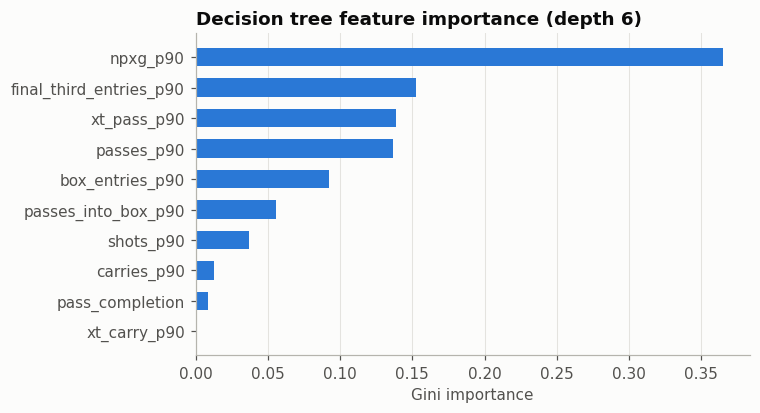

In [16]:
tree = models["Decision tree"].fit(players[FEATURES], y).best_estimator_
importance = pd.Series(tree.feature_importances_, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.barh(importance.index, importance.values, color=SERIES[0], height=0.6)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Gini importance")
ax.set_title(f"Decision tree feature importance (depth {tree.get_depth()})")
plt.show()

## Takeaways

1. **xT is not xG in disguise.** Across outfield regulars, xT per 90 and npxG per 90 are essentially uncorrelated (r = −0.02), and xT from *passing* is negatively correlated with npxG (r = −0.26). The players who move the ball into dangerous areas are mostly not the ones who shoot from them. Forwards earn most of their xT by carrying, defenders and midfielders by passing.
2. **Five archetypes** come out of a 3-component PCA (87% of variance) plus k-means: elite creators, wide carriers, box finishers, build-up players and low-involvement defenders. The two xT components drive the split between creators and carriers, which shot-based metrics cannot see.
3. **Position is largely recoverable from event data.** A tuned KNN classifier labels DEF / MID / FWD correctly about 79% of the time in nested cross-validation, against a 40% majority-class baseline. Most errors are midfielders, the most heterogeneous group. Adding the xT features improves accuracy by only 1 to 2 points, which is within fold-to-fold noise: positions are already well described by volume and shooting metrics. xT's value is in separating styles *within* positions.

**Limitations.** One season, so archetypes reflect 2015/16 tactics. StatsBomb's position label is the position a player spent most minutes in, which blurs players who switch roles. Clusters are descriptive: silhouette ≈ 0.33 means boundaries between roles are soft.